# Energy, Cost, and Emissions Scenarios

This notebook compares three strategies for the hypothetical Loudoun County facility: continued grid reliance, efficiency combined with clean-energy procurement, and a package combining efficiency, flexible operations, and battery storage. I evaluate each scenario using the same hourly baseline and report annual electricity use, peak demand, cost, and location- and market-based emissions.

The analysis is intended to support initial decision screening. It is not an engineering design, tariff study, power-market forecast, or investment-grade estimate.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

# Locate the main project folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Define the folders used in this notebook
PROCESSED = ROOT / "data" / "processed"
TABLES = ROOT / "outputs" / "tables"
FIGURES = ROOT / "outputs" / "figures"

# Create output folders if they do not already exist
PROCESSED.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

scenario_colors = {
    "Grid Baseline": "#7A7A7A",
    "Efficiency + Clean Procurement": "#4B9CD3",
    "Efficiency + Flexible Load + Battery": "#17365D",
}

scenarios = pd.DataFrame([
    {
        "scenario": "Grid Baseline",
        "efficiency_pct": 0.00,
        "renewable_share": 0.00,
        "premium_usd_per_mwh": 0.0,
        "flex_peak_pct": 0.00,
        "battery_mw": 0,
        "battery_mwh": 0,
        "capex_usd": 0,
    },
    {
        "scenario": "Efficiency + Clean Procurement",
        "efficiency_pct": 0.08,
        "renewable_share": 0.80,
        "premium_usd_per_mwh": 6.0,
        "flex_peak_pct": 0.00,
        "battery_mw": 0,
        "battery_mwh": 0,
        "capex_usd": 20_000_000,
    },
    {
        "scenario": "Efficiency + Flexible Load + Battery",
        "efficiency_pct": 0.05,
        "renewable_share": 0.40,
        "premium_usd_per_mwh": 6.0,
        "flex_peak_pct": 0.05,
        "battery_mw": 20,
        "battery_mwh": 80,
        "capex_usd": 45_000_000,
    },
])
scenarios.to_csv(ROOT / "data" / "processed" / "scenario_assumptions.csv", index=False)

scenarios

,scenario,efficiency_pct,renewable_share,premium_usd_per_mwh,flex_peak_pct,battery_mw,battery_mwh,capex_usd
0,Grid Baseline,0.00,0.0,0.0,0.00,0,0,0
1,Efficiency + Clean Procurement,0.08,0.8,6.0,0.00,0,0,20000000
2,Efficiency + Flexible Load + Battery,0.05,0.4,6.0,0.05,20,80,45000000


## Scenario design

**Grid Baseline** represents continued operation using the unmodified facility profile and regional grid electricity.

**Efficiency + Clean Procurement** applies an 8% reduction to hourly demand and matches 80% of the remaining annual electricity use with renewable procurement. The efficiency assumption represents a potential portfolio of IT, airflow, cooling, controls, and electrical-system improvements. A facility audit would be needed to determine the measures and savings available at a real site.

**Efficiency + Flexible Load + Battery** applies a 5% efficiency improvement, shifts 5% of demand out of the highest-load hours, matches 40% of annual electricity use with renewable procurement, and adds a 20 MW/80 MWh battery. The battery is equivalent to four hours of storage at maximum discharge power.

The battery calculation represents one idealized peak-shaving cycle per month with 90% round-trip efficiency. It does not model chronological state of charge, utility dispatch, outages, islanding, backup generators, or critical loads. I therefore interpret its results as potential demand-management effects, not quantified outage resilience.

## Cost assumptions

The analysis uses illustrative cost inputs rather than a site-specific utility tariff or vendor proposal:

- Base electricity price: $70/MWh
- Demand charge: $12/kW-month
- Clean-energy premium: $6 per procured MWh
- Efficiency and clean-procurement capital allowance: $20 million
- Efficiency, controls, and battery capital allowance: $45 million
- Discount rate: 7%
- Capital recovery period: 15 years
- Battery round-trip efficiency: 90%

The $20 million allowance primarily represents implementation of the efficiency package; renewable procurement is treated as an operating premium. The $45 million allowance covers the combined efficiency, control, and battery package. These values make it possible to compare strategies consistently, but they should not be interpreted as project quotations.

In [2]:
# Efficiency and operational load shifting

def adjusted_load(
    base_load,
    efficiency_pct,
    flex_peak_pct,
):
    """
    Apply efficiency improvements and operational load shifting.

    Efficiency reduces load during every hour.
    Flexible operations move electricity consumption from the
    highest-load hours to lower-load hours while preserving energy.
    """
    load = base_load.astype(float).copy()

    # Efficiency reduces electricity use during every hour.
    load *= 1 - efficiency_pct

    # Shift flexible load out of the top 5% of hours.
    if flex_peak_pct > 0:
        peak_mask = load >= load.quantile(0.95)

        shifted_mwh = (
            load.loc[peak_mask]
            * flex_peak_pct
        )

        load.loc[peak_mask] -= shifted_mwh

        # Redistribute the shifted electricity across
        # the lower-load half of the year.
        offpeak_mask = load <= load.quantile(0.50)

        load.loc[offpeak_mask] += (
            shifted_mwh.sum()
            / offpeak_mask.sum()
        )

    return load


# Simplified battery peak-shaving proxy

def apply_battery_peak_shaving(
    load,
    timestamps,
    battery_mw,
    battery_mwh,
    round_trip_efficiency=0.90,
):
    """
    Apply a simplified monthly battery peak-shaving proxy.

    Assumptions:
    - One full battery cycle per month.
    - Discharge targets the highest-load hours.
    - Recharge is spread across 100 low-load hours.
    - Data use one-hour intervals.
    - Monthly peak hours are known in advance.
    """
    result = load.astype(float).copy()

    # Baseline and clean-procurement scenarios have no battery.
    if battery_mw <= 0 or battery_mwh <= 0:
        return result

    timestamp_series = pd.Series(
        pd.to_datetime(timestamps).to_numpy(),
        index=result.index,
    )

    month_labels = timestamp_series.dt.to_period("M")

    for month in month_labels.unique():
        month_index = month_labels.index[
            month_labels == month
        ]

        monthly_load = result.loc[month_index]

        # Example: 80 MWh / 20 MW = four-hour duration.
        discharge_duration_hours = int(
            np.ceil(battery_mwh / battery_mw)
        )

        # Target the highest-load hours in the month.
        discharge_hours = (
            monthly_load
            .nlargest(discharge_duration_hours)
            .index
        )

        remaining_energy_mwh = battery_mwh
        discharged_energy_mwh = 0.0

        for hour_index in discharge_hours:
            # For one-hour intervals, MW discharged during
            # one hour is numerically equivalent to MWh.
            discharge_mwh = min(
                battery_mw,
                remaining_energy_mwh,
                result.loc[hour_index],
            )

            result.loc[hour_index] -= discharge_mwh
            remaining_energy_mwh -= discharge_mwh
            discharged_energy_mwh += discharge_mwh

        # Account for battery losses.
        recharge_energy_mwh = (
            discharged_energy_mwh
            / round_trip_efficiency
        )

        # Do not recharge during the same hours that were discharged.
        possible_charge_hours = (
            result.loc[month_index]
            .drop(index=discharge_hours)
        )

        number_of_charge_hours = min(
            100,
            len(possible_charge_hours),
        )

        charge_hours = (
            possible_charge_hours
            .nsmallest(number_of_charge_hours)
            .index
        )

        charge_mw = (
            recharge_energy_mwh
            / number_of_charge_hours
        )

        if charge_mw > battery_mw:
            raise ValueError(
                "Required charging power exceeds battery rating."
            )

        result.loc[charge_hours] += charge_mw

    return result


# Capital recovery

def capital_recovery_factor(
    rate=0.07,
    years=15,
):
    """
    Convert an up-front capital cost into an equivalent
    annual cost using a 7% rate and 15-year recovery period.
    """
    return (
        rate * (1 + rate) ** years
        / ((1 + rate) ** years - 1)
    )

# Evaluate one scenario

def evaluate_scenario(
    base_df,
    row,
    co2_lb_per_mwh,
    base_energy_price=70.0,
    demand_charge_kw_month=12.0,
    round_trip_efficiency=0.90,
):
    """
    Calculate energy use, peak demand, cost, and emissions
    for one scenario.
    """

    # Step 1: Apply efficiency and flexible operations.
    load = adjusted_load(
        base_load=base_df["load_mw"],
        efficiency_pct=row.efficiency_pct,
        flex_peak_pct=row.flex_peak_pct,
    )

    # Step 2: Apply the simplified battery proxy.
    load = apply_battery_peak_shaving(
        load=load,
        timestamps=base_df["timestamp"],
        battery_mw=row.battery_mw,
        battery_mwh=row.battery_mwh,
        round_trip_efficiency=round_trip_efficiency,
    )

    hourly = pd.DataFrame({
        "timestamp": base_df["timestamp"],
        "load_mw": load,
    })

    hourly["month"] = (
        hourly["timestamp"].dt.to_period("M")
    )

    # One-hour intervals mean that summing MW produces MWh.
    annual_mwh = hourly["load_mw"].sum()

    # Demand charges are based on the maximum load in each month.
    monthly_peak_kw = (
        hourly
        .groupby("month")["load_mw"]
        .max()
        * 1000
    )

    # Annual clean-energy procurement.
    renewable_mwh = (
        annual_mwh
        * row.renewable_share
    )

    # Base energy cost plus the procurement premium applied
    # only to the renewable portion.
    energy_cost_usd = (
        annual_mwh * base_energy_price
        + renewable_mwh * row.premium_usd_per_mwh
    )

    demand_cost_usd = (
        monthly_peak_kw.sum()
        * demand_charge_kw_month
    )

    annualized_capex_usd = (
        row.capex_usd
        * capital_recovery_factor()
    )

    # Location-based emissions use the regional eGRID factor.
    location_based_tco2 = (
        annual_mwh
        * co2_lb_per_mwh
        / 2204.62
    )

    # Simplified annual market-based accounting.
    market_based_tco2 = (
        location_based_tco2
        * (1 - row.renewable_share)
    )

    total_annual_cost_usd = (
        energy_cost_usd
        + demand_cost_usd
        + annualized_capex_usd
    )

    return {
        "scenario": row.scenario,
        "efficiency_pct": row.efficiency_pct,
        "flex_peak_pct": row.flex_peak_pct,
        "battery_mw": row.battery_mw,
        "battery_mwh": row.battery_mwh,
        "annual_mwh": annual_mwh,
        "renewable_mwh": renewable_mwh,
        "peak_mw": hourly["load_mw"].max(),
        "energy_cost_usd": energy_cost_usd,
        "demand_cost_usd": demand_cost_usd,
        "annualized_capex_usd": annualized_capex_usd,
        "total_annual_cost_usd": total_annual_cost_usd,
        "location_based_tco2": location_based_tco2,
        "market_based_tco2": market_based_tco2,
        "renewable_share": row.renewable_share,
    }

# Load inputs and evaluate all scenarios

facility = pd.read_csv(
    PROCESSED / "facility_load_hourly.csv",
    parse_dates=["timestamp"],
)

co2_factor = pd.read_csv(
    PROCESSED / "egrid_emissions_factor.csv"
).loc[0, "co2_lb_per_mwh"]

results = pd.DataFrame([
    evaluate_scenario(
        base_df=facility,
        row=row,
        co2_lb_per_mwh=co2_factor,
    )
    for row in scenarios.itertuples(index=False)
])

results.to_csv(
    TABLES / "scenario_results.csv",
    index=False,
)

results

,scenario,efficiency_pct,flex_peak_pct,battery_mw,battery_mwh,annual_mwh,renewable_mwh,peak_mw,energy_cost_usd,demand_cost_usd,annualized_capex_usd,total_annual_cost_usd,location_based_tco2,market_based_tco2,renewable_share
0,Grid Baseline,0.00,0.00,0,0,744600.000000,0.000000,90.199365,5.212200e+07,1.267851e+07,0.000000e+00,6.480051e+07,200424.466529,200424.466529,0.0
1,Efficiency + Clean Procurement,0.08,0.00,0,0,685032.000000,548025.600000,82.983416,5.124039e+07,1.166423e+07,2.195892e+06,6.510052e+07,184390.509207,36878.101841,0.8
2,Efficiency + Flexible Load + Battery,0.05,0.05,20,80,707476.666667,282990.666667,83.815226,5.122131e+07,1.193097e+07,4.940758e+06,6.809304e+07,190431.954739,114259.172843,0.4


## Modeled results

The baseline facility consumes 744,600 MWh annually, reaches a peak of 90.2 MW, and has a modeled annual cost of $64.8 million.

Efficiency and clean procurement reduce annual consumption by 8% and lower the peak to 83.0 MW. The modeled annual cost rises by approximately $0.3 million, or 0.5%, while simplified market-based emissions fall from about 200,400 to 36,900 metric tons of CO₂.

The efficiency, flexible-load, and battery package lowers the modeled peak to 83.8 MW and produces annual costs of approximately $68.1 million. Most of the peak reduction comes from efficiency and load shifting. Because the facility profile is relatively flat, four hours of battery discharge reveal other nearly equivalent high-load hours, limiting the battery’s effect on the annual peak.

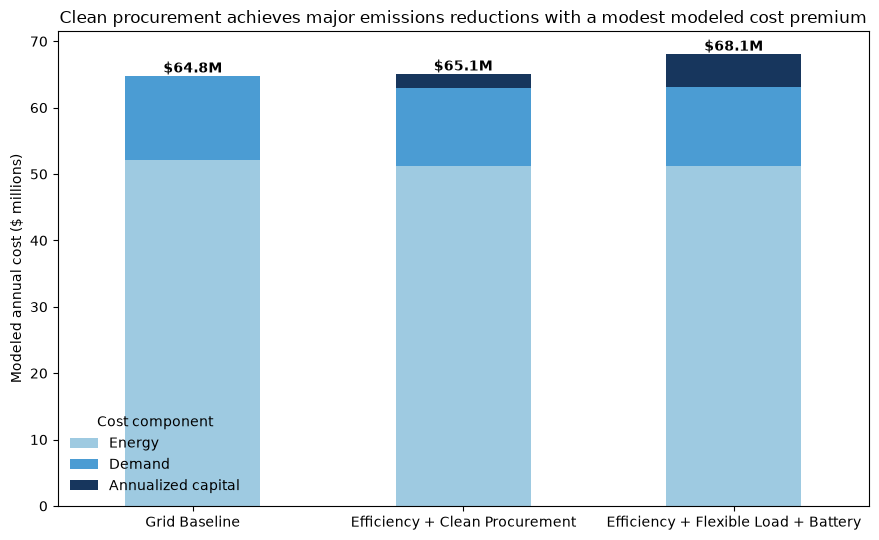

In [3]:
import matplotlib.pyplot as plt

cost_data = (
    results
    .set_index("scenario")
    [
        [
            "energy_cost_usd",
            "demand_cost_usd",
            "annualized_capex_usd"
        ]
    ]
    / 1_000_000
)

cost_data = cost_data.rename(
    columns={
        "energy_cost_usd": "Energy",
        "demand_cost_usd": "Demand",
        "annualized_capex_usd": "Annualized capital"
    }
)

fig, ax = plt.subplots(figsize=(9, 5.5))

cost_data.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[
        "#9ECAE1",
        "#4B9CD3",
        "#17365D"
    ]
)

ax.set_title(
    "Clean procurement achieves major emissions reductions "
    "with a modest modeled cost premium"
)

ax.set_xlabel("")
ax.set_ylabel("Modeled annual cost ($ millions)")
ax.tick_params(axis="x", rotation=0)
ax.legend(
    title="Cost component",
    frameon=False
)

totals = (
    results
    .set_index("scenario")
    ["total_annual_cost_usd"]
    / 1_000_000
)

for position, total in enumerate(totals):
    ax.text(
        position,
        total + 0.5,
        f"${total:.1f}M",
        ha="center",
        fontweight="bold"
    )

fig.tight_layout()

fig.savefig(
    FIGURES / "scenario_annual_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## How emissions are counted

I report two Scope 2 perspectives. Location-based emissions apply the SRVC eGRID factor to all electricity consumed, so they decline only when efficiency reduces total MWh. Market-based emissions also account for contractual renewable procurement.

For this screening model, I use simplified annual matching and assign zero operational emissions to the procured renewable share. This does not mean the facility physically receives renewable electricity during every hour. The calculation does not include residual-mix factors, hourly matching, transmission constraints, certificate quality, or whether the procurement results in additional clean generation.

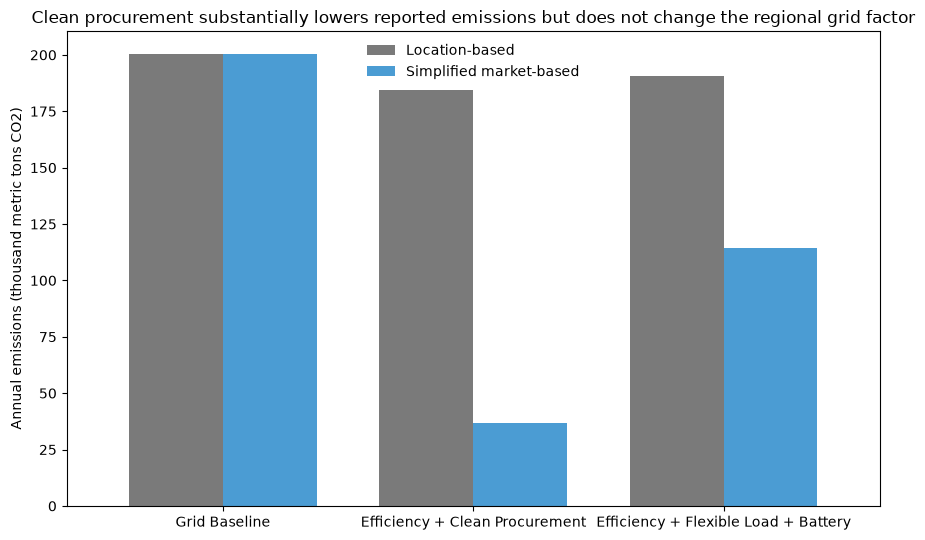

In [4]:
emissions_data = (
    results
    .set_index("scenario")
    [
        [
            "location_based_tco2",
            "market_based_tco2"
        ]
    ]
    / 1_000
)

emissions_data = emissions_data.rename(
    columns={
        "location_based_tco2": "Location-based",
        "market_based_tco2": "Simplified market-based"
    }
)

fig, ax = plt.subplots(figsize=(9, 5.5))

emissions_data.plot(
    kind="bar",
    ax=ax,
    color=[
        "#7A7A7A",
        "#4B9CD3"
    ],
    width=0.75
)

ax.set_title(
    "Clean procurement substantially lowers reported emissions "
    "but does not change the regional grid factor"
)

ax.set_xlabel("")
ax.set_ylabel("Annual emissions (thousand metric tons CO2)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGURES / "scenario_emissions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

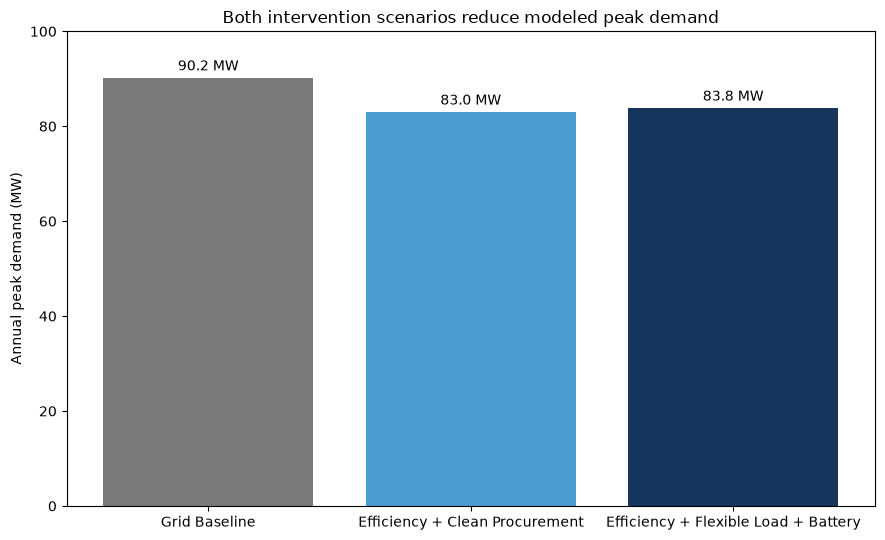

In [5]:
peak_values = results["peak_mw"]

colors = [
    scenario_colors[str(scenario)]
    for scenario in results["scenario"]
]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(
    results["scenario"].astype(str),
    peak_values,
    color=colors
)

ax.set_title(
    "Both intervention scenarios reduce modeled peak demand"
)

ax.set_xlabel("")
ax.set_ylabel("Annual peak demand (MW)")
ax.set_ylim(0, 100)

ax.bar_label(
    bars,
    labels=[
        f"{value:.1f} MW"
        for value in peak_values
    ],
    padding=3
)

fig.tight_layout()

fig.savefig(
    FIGURES / "scenario_peak_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

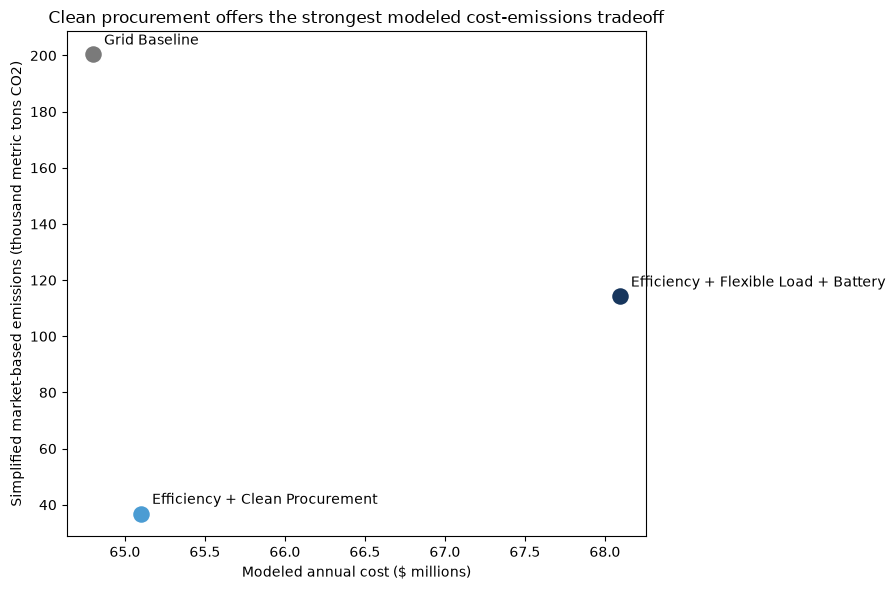

In [6]:
plot_data = results.copy()

plot_data["annual_cost_millions"] = (
    plot_data["total_annual_cost_usd"]
    / 1_000_000
)

plot_data["market_emissions_thousands"] = (
    plot_data["market_based_tco2"]
    / 1_000
)

fig, ax = plt.subplots(figsize=(9, 6))

for _, row in plot_data.iterrows():
    scenario = str(row["scenario"])

    ax.scatter(
        row["annual_cost_millions"],
        row["market_emissions_thousands"],
        s=180,
        color=scenario_colors[scenario],
        edgecolor="white",
        linewidth=1.5
    )

    ax.annotate(
        scenario,
        (
            row["annual_cost_millions"],
            row["market_emissions_thousands"]
        ),
        xytext=(8, 7),
        textcoords="offset points"
    )

ax.set_title(
    "Clean procurement offers the strongest modeled "
    "cost-emissions tradeoff"
)

ax.set_xlabel("Modeled annual cost ($ millions)")
ax.set_ylabel(
    "Simplified market-based emissions "
    "(thousand metric tons CO2)"
)

fig.tight_layout()

fig.savefig(
    FIGURES / "cost_emissions_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Decision takeaway

Under these assumptions, efficiency combined with clean procurement provides the strongest emissions reduction at close to the baseline annual cost. It is the preferred option if the client’s primary objective is reducing reported Scope 2 emissions without a large modeled cost increase.

The battery package reduces peak demand relative to the baseline, but its modeled peak remains slightly higher than the clean-procurement package because it includes a smaller efficiency improvement. Within the battery scenario, flexible operations and storage provide some peak-shaving benefit, although the battery’s incremental effect is limited by the facility’s consistently high load. Potential resilience, capacity, demand-response, and reliability benefits would require a more detailed dispatch and engineering analysis.